# Задача 7

Решить систему уравнений хищник–жертва

$$
    \begin{cases}
        \dot x=a\,x-b\,xy,\\
        \dot y=c\,xy-d\,y
    \end{cases}
$$

методом Рунге–Кутты второго порядка точности при
$a=10$, $b=2$, $c=2$, $d=10$. Нарисовать фазовую траекторию.

---

## Модель и стационарные точки.

Здесь $x$ — численность жертв, $y$ — численность хищников.
Стационарные точки находим из условий $\dot x=\dot y=0$:

$$
    x(a-by)=0, \qquad y(cx-d)=0
    \quad\Rightarrow\quad
    (0,0), \qquad \left(\frac dc,\frac ab\right)=(5,5).
$$

Начальные условия в задаче не заданы. Основной расчёт проведём для
$x(0)=2$, $y(0)=2$. Интервал времени и число шагов задаются
параметрами `t0`, `T`, `N` ниже. Для фазового портрета
возьмём ещё несколько начальных точек.
Все величины задачи объявим отдельными константами.

In [22]:
import numpy as np
import matplotlib.pyplot as plt

a = 10.0
b = 2.0
c = 2.0
d = 10.0
x_star = d / c
y_star = a / b

t0 = 0.0
T = 50.0
z0 = np.array([2.0, 2.0])
N = 10000


def f(t, z):
    x, y = z
    return np.array([a*x - b*x*y, c*x*y - d*y])

## Первый интеграл.

Аналитического решения в элементарных функциях у системы нет,
но есть сохраняющаяся величина. Разделим уравнения друг на друга:

$$
    \frac{dy}{dx}=\frac{y(cx-d)}{x(a-by)}
    \quad\Rightarrow\quad
    \frac{a-by}{y}\,dy=\frac{cx-d}{x}\,dx.
$$

Интегрируя, получаем

$$
    \boxed{H(x,y)=cx-d\ln x+by-a\ln y=\mathrm{const}}.
$$

Функция $H$ имеет единственный минимум в точке $(5,5)$, поэтому
точные фазовые траектории — **замкнутые кривые** $H=\mathrm{const}$
вокруг стационарной точки. Сохранение $H$ используем для проверки
численного решения.

In [23]:
def find_invariant(x, y):
    return c*x - d*np.log(x) + b*y - a*np.log(y)

## Метод Рунге–Кутты второго порядка.

Как в задаче 6, используем явный метод средней точки, но теперь
$\mathbf z=(x,y)$ — вектор, а $\mathbf f$ — вектор-функция:

$$
\begin{aligned}
    \mathbf k_1&=\mathbf f(t_i,\mathbf z_i),\\
    \mathbf k_2&=\mathbf f\!\left(t_i+\frac h2,\mathbf z_i+\frac h2\mathbf k_1\right),\\
    \mathbf z_{i+1}&=\mathbf z_i+h\mathbf k_2.
\end{aligned}
$$

Ошибка одного шага равна $O(h^3)$, глобальная ошибка — $O(h^2)$.
Функции шага и цикла по сетке те же, что в задаче 6;
меняется только то, что $\mathbf z_i$ хранится как строка массива.

In [24]:
def step_rk2(func, t, z, h):
    k1 = func(t, z)
    k2 = func(t + h/2, z + h*k1/2)
    return z + h*k2


def solve_ode(func, t0, T, z0, N, step):
    if not isinstance(N, (int, np.integer)) or N < 1:
        raise ValueError("N должно быть положительным целым числом")
    t = np.linspace(t0, T, N + 1)
    h = (T - t0) / N
    z = np.empty((N + 1, len(z0)))
    z[0] = z0
    for i in range(N):
        z[i+1] = step(func, t[i], z[i], h)
    return t, z

## Решение на сетке.

Используем значения `T` и `N` из первой ячейки: шаг равен
$h=(T-t_0)/N$. Выведем фактический шаг, решение в нескольких узлах
и отклонение $H$ от начального значения. При `T=50`, `N=10000`
получается $h=0.005$.


In [25]:
t_grid, z = solve_ode(f, t0, T, z0, N, step_rk2)
x, y = z[:, 0], z[:, 1]
H = find_invariant(x, y)
H0 = H[0]

print(f"N = {N}, h = {(T-t0)/N:g}")
print(f"{'t':>6} {'x(t)':>14} {'y(t)':>14} {'H - H(0)':>14}")
for i in np.linspace(0, N, 7, dtype=int):
    print(f"{t_grid[i]:6.2f} {x[i]:14.8f} {y[i]:14.8f} {H[i]-H0:14.5e}")

print(f"\nH(0) = {H0:.12f}")
print(f"max |H - H(0)| = {np.max(np.abs(H - H0)):.3e}")
print(f"x от {x.min():.5f} до {x.max():.5f}, y от {y.min():.5f} до {y.max():.5f}")
assert np.all(z > 0)

N = 10000, h = 0.005
     t           x(t)           y(t)       H - H(0)
  0.00     2.00000000     2.00000000    0.00000e+00
  8.33     1.75175904     2.31343168   -1.99406e-04
 16.66     1.59676050     2.61194530   -3.66387e-04
 25.00     1.47299338     2.96331911   -4.97463e-04
 33.33     1.35655207     3.49941898   -5.46149e-04
 41.66     1.29608628     3.99854277   -5.89842e-04
 50.00     1.26273856     4.57558913   -5.83830e-04

H(0) = -5.862943611199
max |H - H(0)| = 2.129e-02
x от 1.25604 до 12.91658, y от 1.25607 до 12.91738


## Фазовая траектория.

Слева — фазовая плоскость $(x,y)$. Кроме основной траектории
построим траектории из точек $(x_0,5)$ с разными $x_0$.
Серым пунктиром нанесены точные линии уровня $H(x,y)=H(x_0,y_0)$:
численные траектории должны с ними совпадать.
Справа — зависимости $x(t)$ и $y(t)$ для основной траектории.

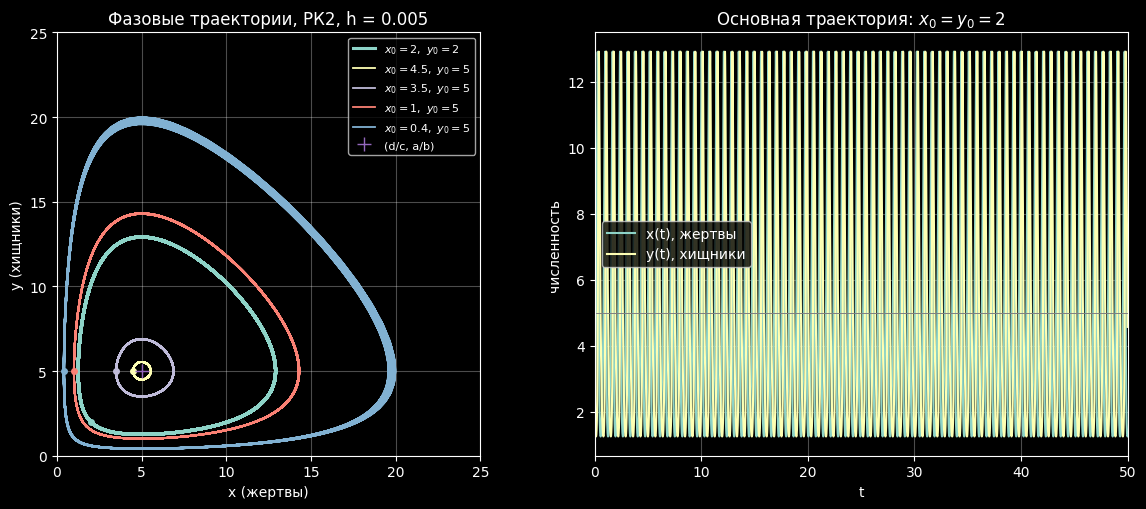

In [26]:
starts = [np.array([x_start, y_star]) for x_start in [4.5, 3.5, 1.0, 0.4]]
phase = [z]
for start in starts:
    phase.append(solve_ode(f, t0, T, start, N, step_rk2)[1])

X, Y = np.meshgrid(np.linspace(0.1, 25, 600), np.linspace(0.1, 25, 600))
levels = sorted(find_invariant(*p[0]) for p in phase)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
ax = axes[0]
ax.contour(X, Y, find_invariant(X, Y), levels=levels,
           colors="gray", linestyles=":", linewidths=1.2)
for k, p in enumerate(phase):
    label = rf"$x_0={p[0, 0]:g},\ y_0={p[0, 1]:g}$"
    ax.plot(p[:, 0], p[:, 1], linewidth=2.2 if k == 0 else 1.3, label=label)
    ax.plot(*p[0], "o", color=ax.lines[-1].get_color(), markersize=4)
ax.plot(x_star, y_star, "+", color="tab:purple", markersize=10, label="(d/c, a/b)")
ax.set(xlabel="x (жертвы)", ylabel="y (хищники)", xlim=(0, 25), ylim=(0, 25),
       title=f"Фазовые траектории, РК2, h = {(T-t0)/N:g}")
ax.set_aspect("equal")
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(t_grid, x, label="x(t), жертвы")
ax.plot(t_grid, y, label="y(t), хищники")
ax.axhline(x_star, color="gray", linewidth=0.7)
ax.set(xlabel="t", ylabel="численность", xlim=(t0, T),
       title=r"Основная траектория: $x_0=y_0=2$")
ax.legend()
for ax in axes:
    ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

Точные фазовые траектории замкнуты и лежат на уровнях $H=\mathrm{const}$.
Численные траектории приближают эти кривые, но не замыкаются строго:
при длительном расчёте может быть заметно наложение смещённых витков.
Движение идёт против часовой стрелки; максимум числа хищников запаздывает
относительно максимума числа жертв. Для выбранной серии начальных точек
более крупным орбитам соответствуют более длительные периоды.


## Малые колебания: проверка периода.

Пусть $x=x_*+\xi$, $y=y_*+\eta$, где $x_*=d/c$, $y_*=a/b$.
Отбрасывая произведение $\xi\eta$, получаем

$$
    \dot\xi=-\frac{bd}{c}\,\eta, \qquad \dot\eta=\frac{ca}{b}\,\xi
    \quad\Rightarrow\quad
    \ddot\xi=-ad\,\xi.
$$

Значит, вблизи стационарной точки частота и период равны

$$
    \omega_0=\sqrt{ad}=10, \qquad
    T_0=\frac{2\pi}{\sqrt{ad}}\approx0.6283.
$$

Численно период найдём по моментам, когда $x-x_*$ меняет знак
с минуса на плюс; момент пересечения уточним линейной интерполяцией.

In [27]:
def find_period(t, x, level):
    s = x - level
    idx = np.where((s[:-1] < 0) & (s[1:] >= 0))[0]
    crossings = t[idx] - s[idx] * (t[idx+1] - t[idx]) / (s[idx+1] - s[idx])
    return np.mean(np.diff(crossings))


T_lin = 2*np.pi / np.sqrt(a*d)
print(f"Линейная теория: T0 = 2π/√(ad) = {T_lin:.6f}")
print(f"{'x0':>6} {'y0':>4} {'Период':>12} {'Период / T0':>13}")
periods = []
for x_start in [5.01, 5.1, 5.5, 4.0, 3.0, 2.0, 1.0, 0.4]:
    t, p = solve_ode(f, t0, T, np.array([x_start, y_star]), N, step_rk2)
    period = find_period(t, p[:, 0], x_star)
    periods.append(period)
    print(f"{x_start:6.2f} {y_star:4.0f} {period:12.6f} {period/T_lin:13.6f}")
assert abs(periods[0] / T_lin - 1) < 1e-3

Линейная теория: T0 = 2π/√(ad) = 0.628319
    x0   y0       Период   Период / T0
  5.01    5     0.628057      0.999584
  5.10    5     0.628078      0.999617
  5.50    5     0.628553      1.000374
  4.00    5     0.630507      1.003484
  3.00    5     0.639823      1.018309
  2.00    5     0.661835      1.053343
  1.00    5     0.715361      1.138533
  0.40    5     0.802174      1.276700


При малой амплитуде период совпадает с $2\pi/\sqrt{ad}$ — это проверка
программы в предельном случае. С ростом амплитуды колебания становятся
нелинейными, и период увеличивается.

## Проверка порядка точности.

Явную формулу решения не используем, поэтому применим два способа.
Порядок проверяем отдельно на фиксированном интервале до `T_order=3`,
чтобы увеличение длительности основного расчёта не делало тестовые сетки чрезмерно грубыми.

1. Сравнение решений на соседних сетках в общих узлах:

$$
    \delta_N=\max_{0\le i\le N}\bigl\|\mathbf z^{(N)}_i-\mathbf z^{(2N)}_{2i}\bigr\|_\infty,
    \qquad p=\log_2\frac{\delta_N}{\delta_{2N}}.
$$

Если ошибка равна $Ch^2$, то $\delta_N\approx\frac34Ch^2$, и $p\to2$.

2. Нарушение первого интеграла $\Delta H_N=\max_i|H(\mathbf z_i)-H(\mathbf z_0)|$.
Для точного решения $\Delta H=0$, поэтому $\Delta H_N$ — это
диагностика нарушения закона сохранения. На этих сетках ожидается
порядок, близкий к двум. Эта величина не измеряет ошибку фазы.

In [28]:
T_order = 3.0  # отдельный короткий интервал проверки порядка
N_values = np.array([375, 750, 1500, 3000, 6000, 12000, 24000])
solutions = {n: solve_ode(f, t0, T_order, z0, n, step_rk2)[1] for n in N_values}

deltas, drifts = [], []
print(f"{'N':>6} {'h':>10} {'δ_N':>12} {'p':>8} {'ΔH_N':>12} {'p_H':>8}")
for k, n in enumerate(N_values):
    drift = np.max(np.abs(find_invariant(*solutions[n].T) - H0))
    p_H = np.log2(drifts[-1] / drift) if drifts else np.nan
    drifts.append(drift)
    if n * 2 in solutions:
        delta = np.max(np.abs(solutions[n] - solutions[2*n][::2]))
        p = np.log2(deltas[-1] / delta) if deltas else np.nan
        deltas.append(delta)
        delta_text = f"{delta:12.4e}"
    else:
        p = np.nan
        delta_text = f"{'—':>12}"
    p_text = f"{p:8.4f}" if np.isfinite(p) else f"{'—':>8}"
    p_H_text = f"{p_H:8.4f}" if np.isfinite(p_H) else f"{'—':>8}"
    print(f"{n:6d} {(T_order-t0)/n:10.6f} {delta_text} {p_text} {drift:12.4e} {p_H_text}")

     N          h          δ_N        p         ΔH_N      p_H
   375   0.008000   7.0298e-02        —   5.4824e-02        —
   750   0.004000   1.7772e-02   1.9839   1.3607e-02   2.0104
  1500   0.002000   4.4678e-03   1.9920   3.3955e-03   2.0027
  3000   0.001000   1.1203e-03   1.9956   8.4852e-04   2.0006
  6000   0.000500   2.8049e-04   1.9979   2.1211e-04   2.0001
 12000   0.000250   7.0172e-05   1.9990   5.3027e-05   2.0000
 24000   0.000125            —        —   1.3257e-05   2.0000


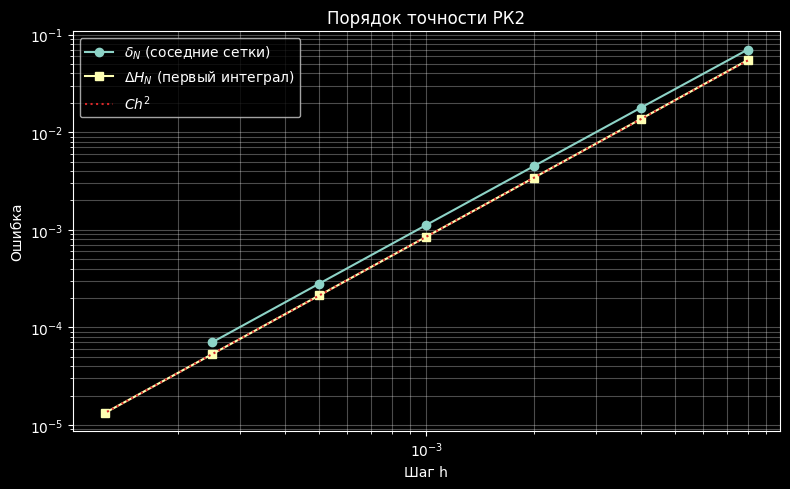

In [29]:
h_values = (T_order - t0) / N_values
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(h_values[:-1], deltas, "o-", label=r"$\delta_N$ (соседние сетки)")
ax.loglog(h_values, drifts, "s-", label=r"$\Delta H_N$ (первый интеграл)")
ax.loglog(h_values, drifts[-1] * (h_values / h_values[-1])**2, linestyle=":", color="tab:red",
          label=r"$C h^2$")
ax.set(xlabel="Шаг h", ylabel="Ошибка", title="Порядок точности РК2")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## Ответ.

Решение системы методом РК2 строится по формулам

$$
\boxed{
\begin{aligned}
    \mathbf k_1&=\mathbf f(t_i,\mathbf z_i),\qquad
    \mathbf k_2=\mathbf f\!\left(t_i+\frac h2,\mathbf z_i+\frac h2\mathbf k_1\right),\\
    \mathbf z_{i+1}&=\mathbf z_i+h\mathbf k_2,\qquad
    \mathbf f(x,y)=\bigl(ax-bxy,\ cxy-dy\bigr).
\end{aligned}}
$$

Стационарная точка $(d/c,\,a/b)=(5,5)$. Фазовые траектории —
замкнутые кривые вокруг неё, на которых сохраняется

$$
    \boxed{H(x,y)=2x-10\ln x+2y-10\ln y=\mathrm{const}}.
$$

В коротком проверочном расчёте при $h=10^{-3}$ величина $H$
сохраняется с абсолютной погрешностью около $10^{-3}$; период малых колебаний совпадает с
$2\pi/\sqrt{ad}\approx0.628$, а наблюдаемый порядок точности равен $2$.
Для малых колебаний РК2 искусственно увеличивает амплитуду,
так как $|q(i\omega_0 h)|>1$. У больших нелинейных орбит
возможны как расширение, так и сжатие.

## Дополнительный вопрос: устойчивость

У точной системы $H=\mathrm{const}$, поэтому каждый оборот повторяет одну
замкнутую кривую. РК2 вычисляет $x,y$ приближённо и не сохраняет $H$ точно:
витки немного смещаются и линия утолщается. Также накапливается ошибка
периода — решение начинает опережать или отставать по времени.

Для малых колебаний около $(5,5)$ множитель усиления РК2 удовлетворяет
$$|q|^2=1+\frac{(\omega h)^4}{4}>1,\qquad \omega=\sqrt{ad}=10.$$
Поэтому малые колебания искусственно усиливаются: абсолютной устойчивости
здесь нет при любом $h>0$. Чем меньше шаг, тем слабее этот эффект на выбранном
времени. Для больших орбит возможны и расширение, и сжатие.

Ниже одна проверка на малой орбите: у точного решения отношение
$(H-H_*)/(H(0)-H_*)$ оставалось бы равным 1. Здесь оно приблизительно
равно отношению квадратов амплитуд.


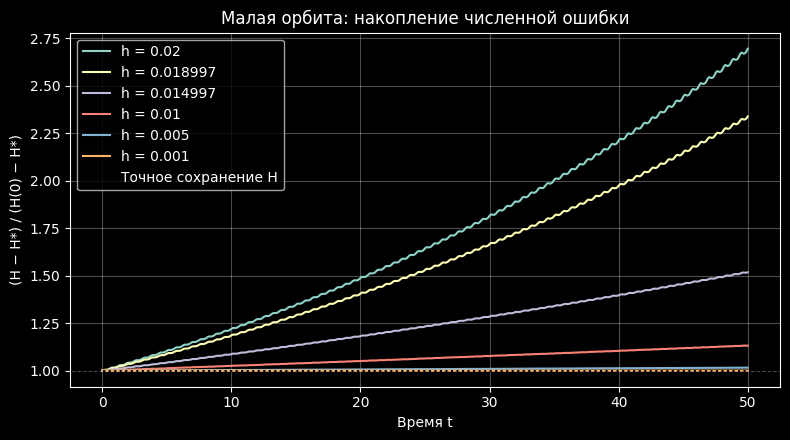

In [31]:
# Меняем шаг при одной и той же длительности расчёта.
T_stability = 50.0
steps_stability = [0.02,0.019,0.015,0.01, 0.005, 0.001]
start_stability = np.array([5.5, 5.0])
H_star_stability = find_invariant(x_star, y_star)
H_initial_stability = find_invariant(*start_stability)

with plt.style.context("dark_background"):
    fig_stability, ax_stability = plt.subplots(figsize=(8, 4.5))
    for h_requested in steps_stability:
        n_stability = int(np.ceil(T_stability / h_requested))
        t_stability, z_stability = solve_ode(
            f, 0.0, T_stability, start_stability, n_stability, step_rk2
        )
        h_actual = T_stability / n_stability
        H_stability = find_invariant(*z_stability.T)
        ratio_stability = (H_stability - H_star_stability) / (H_initial_stability - H_star_stability)
        ax_stability.plot(t_stability, ratio_stability, label=f"h = {h_actual:g}")
    ax_stability.axhline(1, color="black", linestyle=":", label="Точное сохранение H")
    ax_stability.set(xlabel="Время t", ylabel="(H − H*) / (H(0) − H*)",
                     title="Малая орбита: накопление численной ошибки")
    ax_stability.grid(alpha=0.3)
    ax_stability.legend()
    fig_stability.tight_layout()
    plt.show()
